# Radar-Based Activity Recognition Across Age Groups

## Step 1: Data download and inspection

We use the "Radar signatures of human activities" dataset (University of Glasgow, CC BY 4.0), recorded with a 5.8 GHz FMCW radar. It contains about 1,750 recordings of six activities (walking, sitting down, standing up, picking up an object, drinking, and simulated falls) from participants aged 21 to 98, collected in a university lab, a housing association, and an Age UK centre.

The 2 GB archive is downloaded once to Google Drive and extracted to the local disk each session. First, we list the folders and inspect one raw file to understand its format.

In [3]:
import os, time, random, subprocess
import numpy as np
import pandas as pd
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")
assert device == "cuda", "No GPU! Switch the runtime to T4 GPU first."

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(0)

PROJECT_DIR = "/content/drive/MyDrive/phd_projects/radar_har"
DATA_DIR    = os.path.join(PROJECT_DIR, "data")
CKPT_DIR    = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
for d in [DATA_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

URL = "https://researchdata.gla.ac.uk/848/20/Dataset_848.7z"
ARCHIVE = os.path.join(DATA_DIR, "Dataset_848.7z")
if not os.path.exists(ARCHIVE):
    print("Downloading (2 GB, a few minutes)...")
    t0 = time.time()
    subprocess.run(["wget", "-q", "-O", ARCHIVE + ".tmp", URL], check=True)
    os.replace(ARCHIVE + ".tmp", ARCHIVE)
    print(f"Done in {time.time()-t0:.0f}s")
print(f"Archive on Drive: {os.path.getsize(ARCHIVE)/1e9:.2f} GB")

LOCAL_DIR = "/content/radar_raw"
if not os.path.exists(LOCAL_DIR):
    subprocess.run("apt-get -qq install -y p7zip-full > /dev/null", shell=True)
    t0 = time.time()
    subprocess.run(["7z", "x", ARCHIVE, f"-o{LOCAL_DIR}", "-y"], check=True, stdout=subprocess.DEVNULL)
    print(f"Extracted in {time.time()-t0:.0f}s")

dat_files = []
for root, _, files in os.walk(LOCAL_DIR):
    for f in files:
        if f.lower().endswith(".dat"):
            dat_files.append(os.path.relpath(os.path.join(root, f), LOCAL_DIR))
print("Total .dat files:", len(dat_files))
print(pd.Series([os.path.dirname(p) for p in dat_files]).value_counts().to_string())
print("Example names:", sorted(dat_files)[:5])

sample = os.path.join(LOCAL_DIR, sorted(dat_files)[0])
print(f"\nSample file: {sample}  ({os.path.getsize(sample)/1e6:.1f} MB)")
with open(sample, "r", errors="replace") as fh:
    for _ in range(6):
        print(repr(fh.readline()[:80]))

Device: cuda Tesla T4
Done in 218s
Archive on Drive: 2.06 GB
Extracted in 295s
Total .dat files: 1754
1 December 2017 Dataset              360
5 February 2019 UoG Dataset          306
6 February 2019 NG Homes Dataset     301
7 March 2019 West Cumbria Dataset    289
4 July 2018 Dataset                  288
3 June 2017 Dataset                  162
2 March 2017 Dataset                  48
Example names: ['1 December 2017 Dataset/1P36A01R01.dat', '1 December 2017 Dataset/1P36A01R02.dat', '1 December 2017 Dataset/1P36A01R03.dat', '1 December 2017 Dataset/1P37A01R01.dat', '1 December 2017 Dataset/1P37A01R02.dat']

Sample file: /content/radar_raw/1 December 2017 Dataset/1P36A01R01.dat  (15.4 MB)
'5800000000.000000\n'
'1.000000\n'
'128\n'
'400000000.000000\n'
'1812+1897i\n'
'1782+2029i\n'


## Step 2: Radar signal processing

Each file contains a sequence of radar chirps (1 per millisecond, 128 samples each). We turn them into a **micro-Doppler spectrogram**, an image of how fast different body parts move over time:

1. **Reshape** the samples into a matrix: 128 samples (fast time, within one chirp) × number of chirps (slow time, across chirps).
2. **Range FFT:** a Fourier transform within each chirp gives a *range profile*, i.e., the strength of reflections at each distance from the radar.
3. **Clutter removal (MTI filter):** a high-pass filter across chirps removes reflections from static objects such as walls and furniture, which don't change from chirp to chirp. Only moving things remain.
4. **Doppler analysis:** a short-time Fourier transform (STFT) across chirps, at the distances where the person is, measures which velocities are present in each short time window.
5. **Decibel scale:** magnitudes are converted to dB and clipped to a 40 dB range, so both strong (torso) and weak (limbs) movements are visible.

The processing follows the approach commonly used with this dataset.

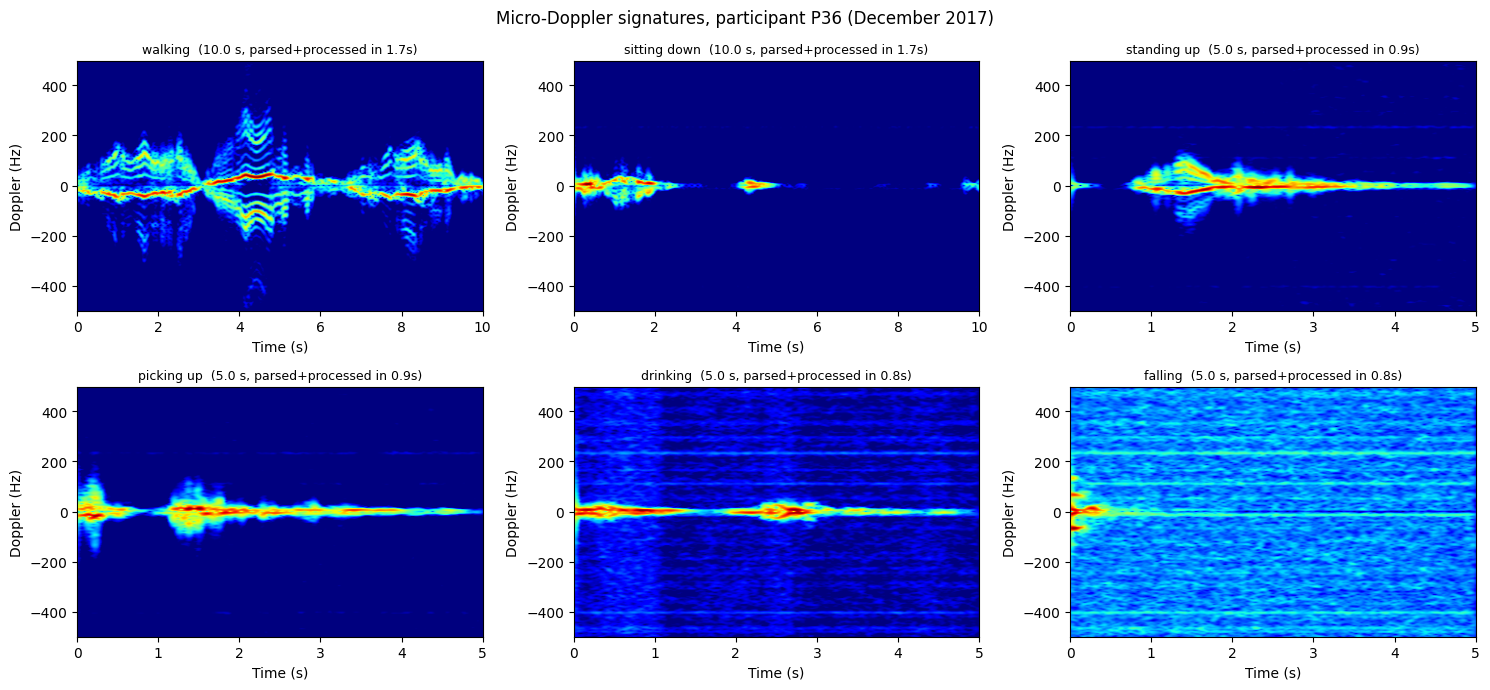

Spectrogram shape (Doppler bins, time frames): (256, 501)


In [4]:
import re
from scipy import signal
import matplotlib.pyplot as plt

def load_radar(path):
    with open(path, "r") as fh:
        head = [fh.readline() for _ in range(4)]       # radar settings
        body = fh.read()
    ns = int(float(head[2]))                            # samples per chirp (128)
    body = body.replace("i", "")
    body = re.sub(r"(\d)([+-])", r"\1 \2", body)       # "1812+1897" -> "1812 +1897"
    vals = np.fromstring(body, sep=" ", dtype=np.float32)
    assert len(vals) % 2 == 0, "parse error: odd number of values"
    iq = vals[0::2] + 1j * vals[1::2]                   # complex samples
    return iq.astype(np.complex64), ns

def micro_doppler(iq, ns=128, prf=1000):
    n_chirps = len(iq) // ns
    x = iq[: n_chirps * ns].reshape(n_chirps, ns).T                 # (fast time, slow time)
    rp = np.fft.fft(x * np.hanning(ns)[:, None], axis=0)[ns // 2:]  # 1. range FFT
    b, a = signal.butter(4, 0.0075, "high")
    rp = signal.lfilter(b, a, rp, axis=1)                           # 2. remove static clutter
    f, t, S = signal.stft(rp[10:30], fs=prf, window="hann", nperseg=200, noverlap=190,
                          nfft=256, return_onesided=False, axis=-1) # 3. Doppler over time
    S = np.abs(np.fft.fftshift(S, axes=1)).sum(axis=0)              # combine range bins
    S_db = 20 * np.log10(S / S.max() + 1e-12)                       # 4. decibels
    return np.fft.fftshift(f), t, np.clip(S_db, -40, 0).astype(np.float32)

ACTIVITIES = {1: "walking", 2: "sitting down", 3: "standing up",
              4: "picking up", 5: "drinking", 6: "falling"}

folder = os.path.join(LOCAL_DIR, "1 December 2017 Dataset")
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, k in zip(axes.ravel(), range(1, 7)):
    path = os.path.join(folder, f"{k}P36A0{k}R01.dat")
    t0 = time.time()
    iq, ns = load_radar(path)
    f, t, S = micro_doppler(iq, ns)
    ax.imshow(S, aspect="auto", origin="lower", cmap="jet", extent=[t[0], t[-1], f[0], f[-1]])
    ax.set_title(f"{ACTIVITIES[k]}  ({len(iq)//ns/1000:.1f} s, parsed+processed in {time.time()-t0:.1f}s)",
                 fontsize=9)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Doppler (Hz)")
plt.suptitle("Micro-Doppler signatures, participant P36 (December 2017)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "spectrogram_examples.png"), dpi=150); plt.show()
print("Spectrogram shape (Doppler bins, time frames):", S.shape)

## Step 2b: Fixing the filter artifact, faster parsing, and checking falls

- **Faster parsing:** plain string replacements (`"+"` → `" +"`, `"-"` → `" -"`) instead of a regular expression.
- **Zero-phase filtering:** the clutter filter now runs forwards and then backwards over each recording (`sosfiltfilt`). This removes the start-up artifact at t = 0 and avoids shifting the signal in time.
- **Diagnostics for falls:** a **range-time map** shows at which distance from the radar movement occurs, so we can check whether the fall happens inside the range bins we analyze (10–30). We also plot falls from several other participants.

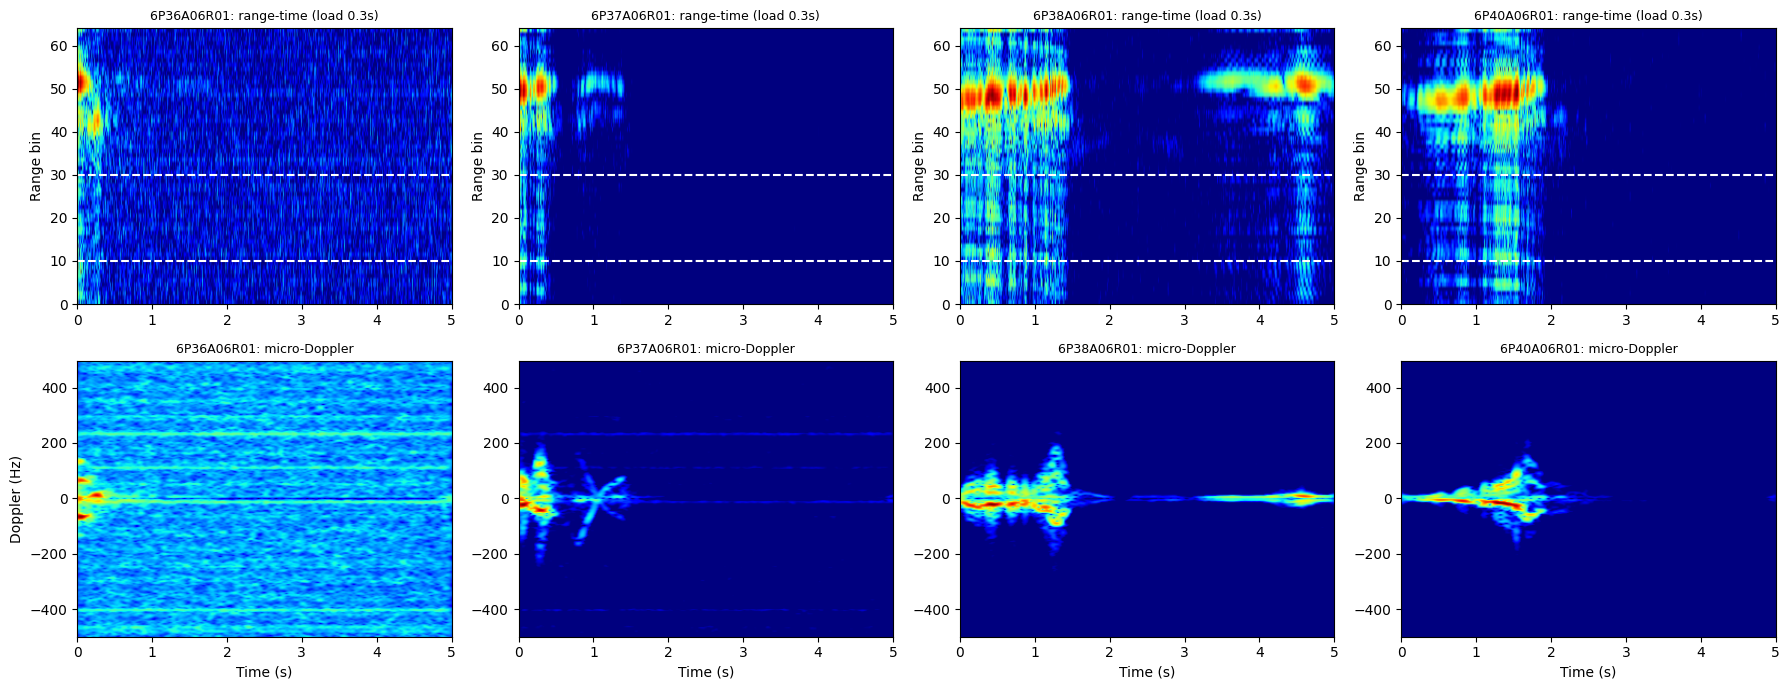

In [5]:
def load_radar(path):
    with open(path, "r") as fh:
        head = [fh.readline() for _ in range(4)]
        body = fh.read()
    ns = int(float(head[2]))
    body = body.replace("i", "").replace("+", " +").replace("-", " -")   # fast, no regex
    vals = np.fromstring(body, sep=" ", dtype=np.float32)
    assert len(vals) % 2 == 0, "parse error: odd number of values"
    return (vals[0::2] + 1j * vals[1::2]).astype(np.complex64), ns

SOS = signal.butter(4, 0.0075, "high", output="sos")

def range_profiles(iq, ns=128):
    n_chirps = len(iq) // ns
    x = iq[: n_chirps * ns].reshape(n_chirps, ns).T
    rp = np.fft.fft(x * np.hanning(ns)[:, None], axis=0)[ns // 2:]
    # zero-phase clutter removal, applied to real and imaginary parts separately
    return signal.sosfiltfilt(SOS, rp.real, axis=1) + 1j * signal.sosfiltfilt(SOS, rp.imag, axis=1)

def micro_doppler(iq, ns=128, prf=1000, rbins=(10, 30)):
    rp = range_profiles(iq, ns)
    f, t, S = signal.stft(rp[rbins[0]:rbins[1]], fs=prf, window="hann", nperseg=200,
                          noverlap=190, nfft=256, return_onesided=False, axis=-1)
    S = np.abs(np.fft.fftshift(S, axes=1)).sum(axis=0)
    S_db = 20 * np.log10(S / S.max() + 1e-12)
    return np.fft.fftshift(f), t, np.clip(S_db, -40, 0).astype(np.float32)

fall_files = ["6P36A06R01", "6P37A06R01", "6P38A06R01", "6P40A06R01"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, name in enumerate(fall_files):
    t0 = time.time()
    iq, ns = load_radar(os.path.join(folder, name + ".dat"))
    load_time = time.time() - t0
    rp = range_profiles(iq, ns)
    rt = 20 * np.log10(np.abs(rp[:, ::10]) + 1e-6)                    # range-time map (every 10th chirp)
    axes[0, col].imshow(rt, aspect="auto", origin="lower", cmap="jet",
                        vmin=rt.max() - 40, vmax=rt.max(), extent=[0, len(iq)//ns/1000, 0, rp.shape[0]])
    axes[0, col].axhline(10, c="w", ls="--"); axes[0, col].axhline(30, c="w", ls="--")
    axes[0, col].set_title(f"{name}: range-time (load {load_time:.1f}s)", fontsize=9)
    axes[0, col].set_ylabel("Range bin")
    f, t, S = micro_doppler(iq, ns)
    axes[1, col].imshow(S, aspect="auto", origin="lower", cmap="jet", extent=[t[0], t[-1], f[0], f[-1]])
    axes[1, col].set_title(f"{name}: micro-Doppler", fontsize=9)
    axes[1, col].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Doppler (Hz)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fall_diagnostics.png"), dpi=150); plt.show()

## Step 3: Processing the full dataset

Each of the 1,754 recordings is converted into a fixed-size micro-Doppler spectrogram and cached on Drive, so this slow step runs only once.

- **Adaptive range window:** for each recording, we find the range bin with the most motion energy and analyze ±10 bins around it. Participants stood at different distances in different rooms, so a fixed range band would miss the person in some recordings.
- **Fixed length:** recordings last 5 or 10 seconds. From each, we keep the 4.8-second window containing the most movement.
- **Absolute levels preserved:** spectrograms are stored in absolute decibels, *without* per-recording scaling. This matters for our experiment: signal strength differs between people, rooms, and distances, and comparing global vs. per-person normalization only makes sense if the raw levels are kept.
- **Downsampling:** 256 Doppler bins × 480 time frames are averaged down to 128 × 240 to save memory and training time.
- **Metadata:** the activity, participant, session, location, and age (from the dataset's readme) are recorded for each file. Participant IDs are reused across sessions, so a participant is identified by session *and* ID.

Two CPU processes run in parallel to speed this up.

In [6]:
import re
from concurrent.futures import ProcessPoolExecutor

AGES = {
 1: {36:27,37:27,38:28,39:23,40:22,41:23,42:22,43:25,44:27,45:25,46:31,47:27,48:34,50:24,51:26,52:26,53:21,54:21,55:23,56:32},
 2: {3:23,10:23,11:23,12:31},
 3: {14:None,28:27,29:27,30:23,31:23,32:26,33:24,34:None,35:36},
 4: {57:32,58:25,59:32,60:25,61:27,62:26,63:27,64:28,65:23,66:26,67:27,68:25,69:36,70:26,71:24,72:28},
 5: {1:25,2:37,3:32,4:36,5:31,6:44,7:34,8:33,9:30,10:27,11:25,12:25,13:31,14:32,15:27,16:25,17:25},
 6: {8:33,18:65,19:82,20:78,21:66,22:33,23:50,24:56,25:25,26:88,27:63,28:79,29:68,30:65,31:24,32:84,
     33:79,34:60,35:64,36:70},
 7: {37:75,38:74,39:52,40:48,41:84,42:85,43:67,44:45,45:78,46:67,47:98,48:47,49:57,50:71,51:50,52:49,
     53:84,54:69,55:57,56:25},
}
LOCATION = {1: "lab", 2: "lab", 3: "lab", 4: "lab", 5: "lab", 6: "NG Homes", 7: "Age UK"}
NAME_RE = re.compile(r"^(\d)P(\d+)A(\d+)R(\d+)\.dat$", re.IGNORECASE)
W = 480   # time frames kept (4.8 s)

def process(relpath):
    session = int(os.path.basename(os.path.dirname(relpath))[0])
    m = NAME_RE.match(os.path.basename(relpath))
    if m is None:
        return None, dict(file=relpath, error="name")
    act, pid, rep = int(m.group(1)), int(m.group(2)), int(m.group(4))
    iq, ns = load_radar(os.path.join(LOCAL_DIR, relpath))
    rp = range_profiles(iq, ns)
    energy = (np.abs(rp[3:]) ** 2).sum(axis=1)                         # motion energy per range bin
    energy = np.convolve(energy, np.ones(5) / 5, mode="same")          # smooth
    center = int(np.argmax(energy)) + 3
    lo, hi = max(3, center - 10), min(rp.shape[0], center + 11)
    f, t, S = signal.stft(rp[lo:hi], fs=1000, window="hann", nperseg=200, noverlap=190,
                          nfft=256, return_onesided=False, axis=-1)
    S = np.abs(np.fft.fftshift(S, axes=1)).sum(axis=0)
    S_db = 20 * np.log10(S + 1e-6)                                     # absolute dB, no per-file scaling
    frame_energy = S.sum(axis=0)
    if S_db.shape[1] < W:
        S_db = np.pad(S_db, ((0, 0), (0, W - S_db.shape[1])), mode="edge")
        frame_energy = np.pad(frame_energy, (0, W - len(frame_energy)))
    csum = np.concatenate([[0], np.cumsum(frame_energy)])
    start = int(np.argmax(csum[W:] - csum[:-W]))                       # most active 4.8 s window
    S_db = S_db[:, start:start + W]
    S_small = S_db.reshape(128, 2, 240, 2).mean(axis=(1, 3))           # 256x480 -> 128x240
    meta = dict(file=relpath, session=session, location=LOCATION[session], pid=pid,
                subject=f"S{session}_P{pid:02d}", activity=act, rep=rep,
                age=AGES[session].get(pid), duration_s=len(iq) / ns / 1000,
                range_center=center, motion_db=float(10 * np.log10(frame_energy.sum() + 1e-12)))
    return S_small.astype(np.float16), meta

CACHE = os.path.join(DATA_DIR, "spectrograms.npz")
META_CSV = os.path.join(DATA_DIR, "metadata.csv")

if not os.path.exists(CACHE):
    t0 = time.time()
    specs, metas, errors = [], [], []
    with ProcessPoolExecutor(max_workers=2) as pool:
        for i, (S, meta) in enumerate(pool.map(process, sorted(dat_files), chunksize=8)):
            if S is None:
                errors.append(meta)
            else:
                specs.append(S); metas.append(meta)
            if (i + 1) % 200 == 0:
                print(f"{i+1}/{len(dat_files)} files  ({time.time()-t0:.0f}s)")
    np.savez_compressed(CACHE + ".tmp.npz", X=np.stack(specs))
    os.replace(CACHE + ".tmp.npz", CACHE)
    pd.DataFrame(metas).to_csv(META_CSV, index=False)
    print(f"Processed {len(specs)} files in {time.time()-t0:.0f}s, errors: {errors}")

X = np.load(CACHE)["X"]
meta = pd.read_csv(META_CSV)
print("Spectrograms:", X.shape, X.dtype)
print("\nRecordings per location and activity:")
print(pd.crosstab(meta["location"], meta["activity"].map(ACTIVITIES)))
print("\nParticipants per location:", meta.groupby("location")["subject"].nunique().to_dict())
print("Age range per location:", meta.groupby("location")["age"].agg(["min", "max"]).to_dict("index"))
print("Range center bins (min/median/max):", meta["range_center"].min(),
      meta["range_center"].median(), meta["range_center"].max())

200/1754 files  (90s)
400/1754 files  (159s)
600/1754 files  (244s)
800/1754 files  (318s)
1000/1754 files  (399s)
1200/1754 files  (482s)
1400/1754 files  (562s)
1600/1754 files  (650s)
Processed 1752 files in 707s, errors: [{'file': '3 June 2017 Dataset/4P30A04R3 (2).dat', 'error': 'name'}, {'file': '4 July 2018 Dataset/4P64A04R3 - Copy.dat', 'error': 'name'}]
Spectrograms: (1752, 128, 240) float16

Recordings per location and activity:
activity  drinking  falling  picking up  sitting down  standing up  walking
location                                                                   
Age UK          57        0          57            58           57       60
NG Homes        60        3          60            60           60       58
lab            193      195         192           194          194      194

Participants per location: {'Age UK': 20, 'NG Homes': 20, 'lab': 66}
Age range per location: {'Age UK': {'min': 25.0, 'max': 98.0}, 'NG Homes': {'min': 24.0, 'max': 88.0}, 'lab

## Step 4: Experimental design

**Task:** classify 5 everyday activities (walking, sitting down, standing up, picking up an object, drinking). Falls are excluded from the cross-age experiment because almost none were recorded outside the lab.

**Splits by participant, not by recording.** Every recording of a person goes into the same split. Otherwise, the model could recognize *the person* rather than the activity, and test results would be inflated.

| Split | Who | Purpose |
|---|---|---|
| train / val / test_lab | Lab participants (ages 21–44), split 70/15/15 by participant | Training, model selection, and in-domain test |
| test_comm_young | Community participants under 60 | Effect of a new location |
| test_60plus | Community participants aged 60+ | Effect of a new location *and* older age |

Comparing the last two test groups separates the effect of location from the effect of age.

activity         drinking  picking up  sitting down  standing up  walking
split                                                                    
test_60plus            72          72            73           72       74
test_comm_young        45          45            45           45       44
test_lab               32          31            31           32       32
train                 135         135           137          136      136
val                    26          26            26           26       26 

                 participants  recordings  mean_age
split                                              
test_60plus                25         363      74.2
test_comm_young            15         224      43.4
test_lab                   11         158      26.2
train                      46         679      27.3
val                         9         130      29.4 

Signal levels by split (absolute dB):
                   mean_db    peak_db  range_center
split                   

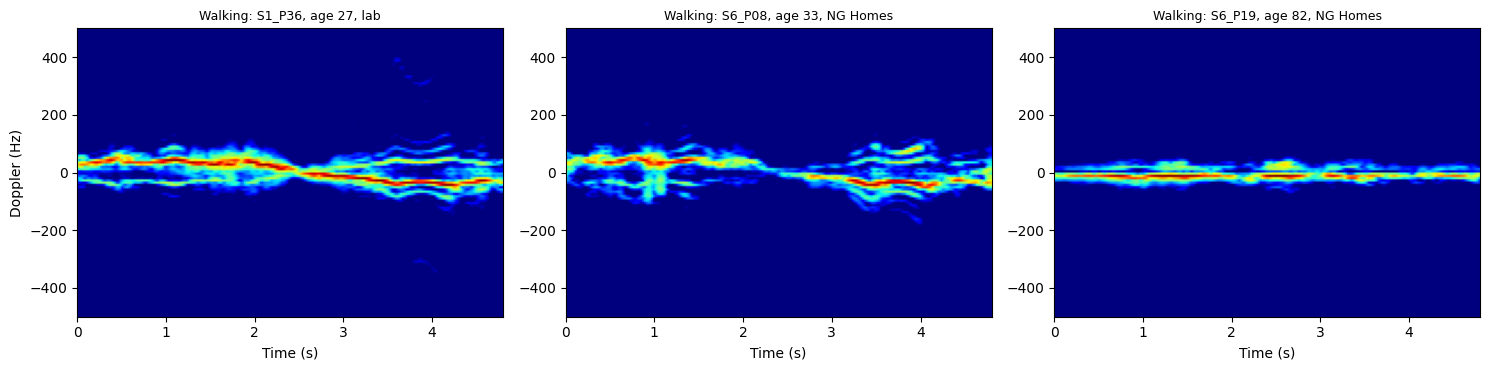

In [7]:
Xf = X.astype(np.float32)
meta["group"] = np.select([meta["location"] == "lab", meta["age"] >= 60],
                          ["lab", "community 60+"], default="community <60")

lab_subjects = sorted(meta.loc[meta["location"] == "lab", "subject"].unique())
rng = np.random.RandomState(0)
rng.shuffle(lab_subjects)
n_tr, n_va = int(0.70 * len(lab_subjects)), int(0.15 * len(lab_subjects))
split_of = {s: "train" for s in lab_subjects[:n_tr]}
split_of.update({s: "val" for s in lab_subjects[n_tr:n_tr + n_va]})
split_of.update({s: "test_lab" for s in lab_subjects[n_tr + n_va:]})

meta["split"] = meta["subject"].map(split_of)
meta.loc[meta["group"] == "community <60", "split"] = "test_comm_young"
meta.loc[meta["group"] == "community 60+", "split"] = "test_60plus"
meta.loc[meta["activity"] == 6, "split"] = "unused"                    # falls
meta["label"] = meta["activity"] - 1                                    # 0..4

used = meta[meta["split"] != "unused"]
print(pd.crosstab(used["split"], used["activity"].map(ACTIVITIES)), "\n")
print(used.groupby("split").agg(participants=("subject", "nunique"), recordings=("file", "count"),
                                 mean_age=("age", "mean")).round(1), "\n")

meta["mean_db"] = Xf.reshape(len(Xf), -1).mean(axis=1)
meta["peak_db"] = Xf.reshape(len(Xf), -1).max(axis=1)
print("Signal levels by split (absolute dB):")
print(meta[meta["split"] != "unused"].groupby("split")[["mean_db", "peak_db", "range_center"]].mean().round(1))
meta.to_csv(os.path.join(DATA_DIR, "metadata_splits.csv"), index=False)

examples = [("lab", None), ("community <60", None), ("community 60+", 80)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (grp, min_age) in zip(axes, examples):
    rows = meta[(meta["group"] == grp) & (meta["activity"] == 1)]
    if min_age:
        rows = rows[rows["age"] >= min_age]
    r = rows.iloc[0]
    S = Xf[r.name]
    ax.imshow(S, aspect="auto", origin="lower", cmap="jet", vmin=S.max() - 40, vmax=S.max(),
              extent=[0, 4.8, -500, 500])
    ax.set_title(f"Walking: {r['subject']}, age {r['age']:.0f}, {r['location']}", fontsize=9)
    ax.set_xlabel("Time (s)")
axes[0].set_ylabel("Doppler (Hz)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "walking_by_group.png"), dpi=150); plt.show()

## Step 5: Training with three normalization strategies

**Model:** ResNet-18 pre-trained on ImageNet, adapted to 1-channel input (`timm` sums the pretrained RGB filters of the first layer into one channel). A CNN suits this small dataset (679 training recordings) better than a Vision Transformer, which typically needs more data.

**Normalization strategies:**
- **Global:** one mean and standard deviation computed from all training spectrograms (the baseline).
- **Per-recording:** each spectrogram is standardized by its own statistics, as in the BloodMNIST study.
- **Per-person:** each participant's spectrograms are standardized by statistics computed from *all of that person's recordings*. No labels are needed, so this is realistic: a sensor installed in someone's home collects their unlabeled data over time and can learn their personal baseline.

**Augmentation:** random time shifts, and random Doppler flips (mirroring the velocity axis swaps "toward the radar" and "away from the radar", which doesn't change the activity).

**Protocol:** 3 seeds per strategy, 30 epochs each. The best epoch is chosen on the *lab* validation set only; community data is never used for any decision. Results are saved after every run, so an interrupted session resumes where it stopped.

In [8]:
import timm
import torch.nn.functional as F

y = torch.tensor(meta["label"].values, device=device)
idx = {s: np.where(meta["split"] == s)[0] for s in ["train", "val", "test_lab", "test_comm_young", "test_60plus"]}
TESTS = ["test_lab", "test_comm_young", "test_60plus"]

def normalize(mode):
    Z = Xf.copy()
    if mode == "global":
        tr = Xf[idx["train"]]
        Z = (Z - tr.mean()) / tr.std()
    elif mode == "per_recording":
        m = Z.mean(axis=(1, 2), keepdims=True); s = Z.std(axis=(1, 2), keepdims=True)
        Z = (Z - m) / s
    elif mode == "per_person":
        for subj, rows in meta[meta["split"] != "unused"].groupby("subject").groups.items():
            r = np.array(list(rows))
            Z[r] = (Z[r] - Z[r].mean()) / Z[r].std()          # this person's own statistics
    return torch.tensor(Z, device=device).unsqueeze(1)          # (N, 1, 128, 240)

def augment(xb):
    xb = torch.roll(xb, shifts=int(torch.randint(-60, 61, (1,))), dims=3)   # time shift
    flip = torch.rand(len(xb), device=device) < 0.5
    xb[flip] = xb[flip].flip(2)                                              # Doppler flip
    return xb

@torch.no_grad()
def evaluate_split(model, Z, ix):
    model.eval()
    preds = []
    for i in range(0, len(ix), 128):
        b = torch.tensor(ix[i:i + 128], device=device)
        with torch.autocast("cuda", dtype=torch.float16):
            preds.append(model(Z[b]).argmax(1))
    p = torch.cat(preds).cpu().numpy(); l = meta["label"].values[ix]
    return float((p == l).mean()), float(np.mean([(p[l == c] == c).mean() for c in range(5)]))

def run(mode, seed, Z, epochs=30):
    set_seed(seed)
    model = timm.create_model("resnet18", pretrained=True, num_classes=5, in_chans=1, drop_rate=0.2).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda")
    tr = torch.tensor(idx["train"], device=device)
    best_val, best_state = -1.0, None
    for ep in range(epochs):
        model.train()
        perm = tr[torch.randperm(len(tr), device=device)]
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            with torch.autocast("cuda", dtype=torch.float16):
                loss = F.cross_entropy(model(augment(Z[b].clone())), y[b])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        val_acc, _ = evaluate_split(model, Z, idx["val"])
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, os.path.join(CKPT_DIR, f"{mode}_seed{seed}.pt"))
    res = dict(mode=mode, seed=seed, val=best_val)
    for s in TESTS:
        res[s], res[s + "_bal"] = evaluate_split(model, Z, idx[s])
    return res

RES = os.path.join(RESULTS_DIR, "results.csv")
done = pd.read_csv(RES) if os.path.exists(RES) else pd.DataFrame(columns=["mode", "seed"])
for mode in ["global", "per_recording", "per_person"]:
    Z = normalize(mode)
    for seed in [0, 1, 2]:
        if ((done["mode"] == mode) & (done["seed"] == seed)).any():
            continue                                             # already done (resume)
        t0 = time.time()
        r = run(mode, seed, Z)
        done = pd.concat([done, pd.DataFrame([r])], ignore_index=True)
        done.to_csv(RES, index=False)
        print(f"{mode:14s} seed {seed} | val {r['val']*100:5.1f} | lab {r['test_lab']*100:5.1f} | "
              f"comm<60 {r['test_comm_young']*100:5.1f} | 60+ {r['test_60plus']*100:5.1f} | {time.time()-t0:.0f}s")
    del Z; torch.cuda.empty_cache()

summary = (done.groupby("mode")[TESTS].agg(["mean", "std"]) * 100).round(1)
print("\nTest accuracy (%), mean and std over 3 seeds:")
print(summary.loc[["global", "per_recording", "per_person"]].to_string())

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

global         seed 0 | val  96.2 | lab  94.9 | comm<60  79.5 | 60+  64.7 | 30s


global         seed 1 | val  98.5 | lab  92.4 | comm<60  79.9 | 60+  67.5 | 23s
global         seed 2 | val  96.9 | lab  93.7 | comm<60  75.4 | 60+  69.7 | 23s
per_recording  seed 0 | val  96.9 | lab  92.4 | comm<60  83.9 | 60+  68.6 | 25s
per_recording  seed 1 | val  97.7 | lab  94.3 | comm<60  84.4 | 60+  67.8 | 25s
per_recording  seed 2 | val  96.2 | lab  89.9 | comm<60  72.3 | 60+  64.7 | 25s
per_person     seed 0 | val  96.9 | lab  94.9 | comm<60  85.3 | 60+  71.6 | 24s
per_person     seed 1 | val  96.9 | lab  93.0 | comm<60  87.9 | 60+  68.9 | 25s
per_person     seed 2 | val  96.2 | lab  93.7 | comm<60  87.5 | 60+  69.4 | 25s

Test accuracy (%), mean and std over 3 seeds:
              test_lab      test_comm_young      test_60plus     
                  mean  std            mean  std        mean  std
mode                                                             
global            93.7  1.3            78.3  2.5        67.3  2.5
per_recording     92.2  2.2            80.2  6.8 

## Step 6: Error analysis and uncertainty

Using the three per-person-normalized models as an ensemble (averaging their predicted probabilities), we examine:

- **Confusion matrices** for each test group: which activities get confused with which, especially for older adults.
- **Predictive entropy** as an uncertainty measure: high entropy means the ensemble spreads its probability across several activities. If uncertainty is higher for wrong predictions, the system could flag doubtful cases for a human to check.
- **Selective prediction:** accuracy on the 80% of recordings where the ensemble is most confident. This simulates a system that defers the most uncertain 20% to a carer.

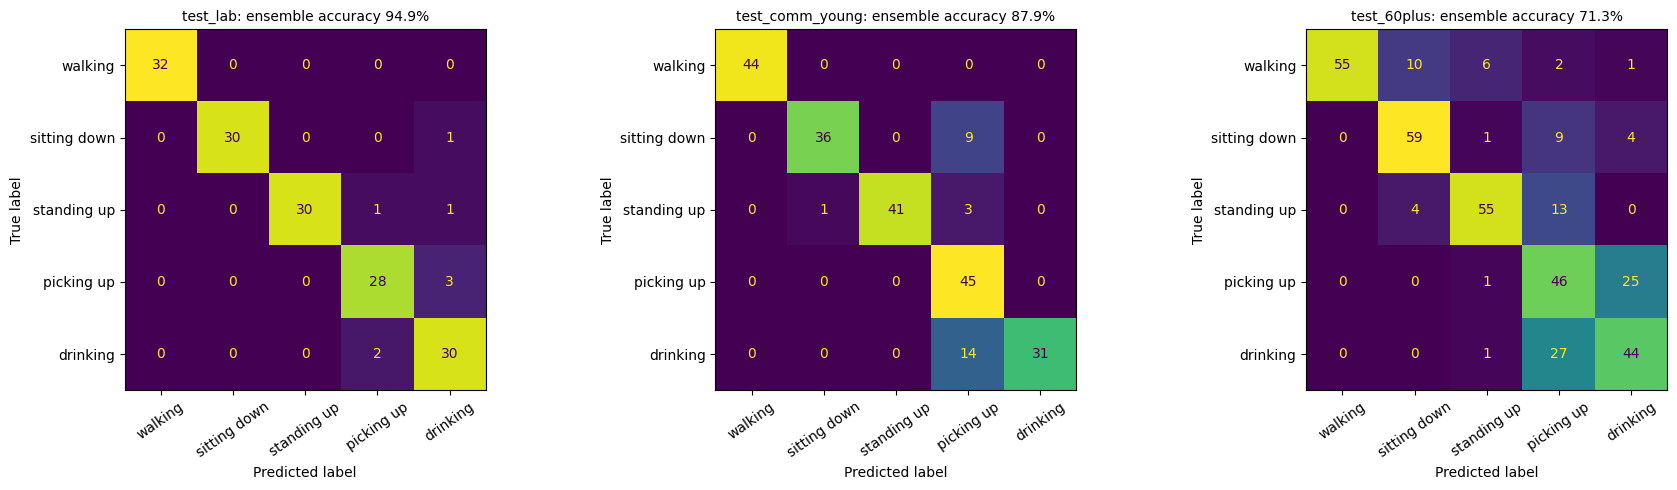

split                    test_lab  test_comm_young  test_60plus
ensemble acc                94.94            87.95        71.35
entropy (correct)            0.11             0.20         0.35
entropy (wrong)              0.69             0.65         0.68
acc, most confident 80%     99.21            95.53        76.90
acc: walking               100.00           100.00        74.32
acc: sitting down           96.77            80.00        80.82
acc: standing up            93.75            91.11        76.39
acc: picking up             90.32           100.00        63.89
acc: drinking               93.75            68.89        61.11


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Z = normalize("per_person")

@torch.no_grad()
def predict_probs(model, ix):
    model.eval()
    out = []
    for i in range(0, len(ix), 128):
        b = torch.tensor(ix[i:i + 128], device=device)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(F.softmax(model(Z[b]).float(), dim=1))
    return torch.cat(out).cpu().numpy()

P = {s: [] for s in TESTS}
for seed in [0, 1, 2]:
    model = timm.create_model("resnet18", pretrained=False, num_classes=5, in_chans=1, drop_rate=0.2).to(device)
    model.load_state_dict(torch.load(os.path.join(CKPT_DIR, f"per_person_seed{seed}.pt"), map_location=device))
    for s in TESTS:
        P[s].append(predict_probs(model, idx[s]))

names = [ACTIVITIES[k] for k in range(1, 6)]
rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, TESTS):
    pm = np.mean(P[s], axis=0)                              # ensemble probabilities
    pred, l = pm.argmax(1), meta["label"].values[idx[s]]
    ent = -(pm * np.log(pm + 1e-12)).sum(1)                 # predictive entropy
    correct = pred == l
    confident = np.argsort(ent)[: int(0.8 * len(ent))]      # most confident 80%
    rows.append({"split": s, "ensemble acc": correct.mean() * 100,
                 "entropy (correct)": ent[correct].mean(), "entropy (wrong)": ent[~correct].mean(),
                 "acc, most confident 80%": correct[confident].mean() * 100,
                 **{f"acc: {n}": (pred[l == c] == c).mean() * 100 for c, n in enumerate(names)}})
    ConfusionMatrixDisplay(confusion_matrix(l, pred, labels=range(5)), display_labels=names).plot(
        ax=ax, xticks_rotation=35, colorbar=False)
    ax.set_title(f"{s}: ensemble accuracy {correct.mean()*100:.1f}%", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "confusion_per_person.png"), dpi=150); plt.show()

analysis = pd.DataFrame(rows).set_index("split").T.round(2)
analysis.to_csv(os.path.join(RESULTS_DIR, "error_uncertainty_analysis.csv"))
print(analysis.to_string())

## Step 7: Few-shot personalization for older adults

Can a few labeled examples from an individual close the age gap? For each of the 25 participants aged 60+:

- One recording per activity is held out as that person's test set.
- The trained per-person-normalized model is fine-tuned on **k = 1 or 2 labeled recordings per activity** from the same person (5 or 10 recordings in total).
- **k = 0** (no fine-tuning) is evaluated on the same held-out recordings, so all conditions are directly comparable.

Fine-tuning uses a low learning rate (1e-4) and 30 steps, with augmentation. Batch-normalization statistics are frozen, because statistics estimated from 5–10 examples would be unreliable. This is repeated for all 3 trained models (seeds), and their predictions are also combined as an ensemble.

25 participants, 122 held-out test recordings
seed 0 done (41s)
seed 1 done (79s)
seed 2 done (118s)
labeled examples per activity     0      1      2
accuracy (mean of seeds)       73.2   82.8   89.6
std                             1.0    0.7    1.4
ensemble accuracy              77.0   88.5   92.6
ens: walking                   72.0   96.0  100.0
ens: sitting down              88.0   88.0   92.0
ens: standing up               79.2   95.8   95.8
ens: picking up                66.7   62.5   83.3
ens: drinking                  79.2  100.0   91.7


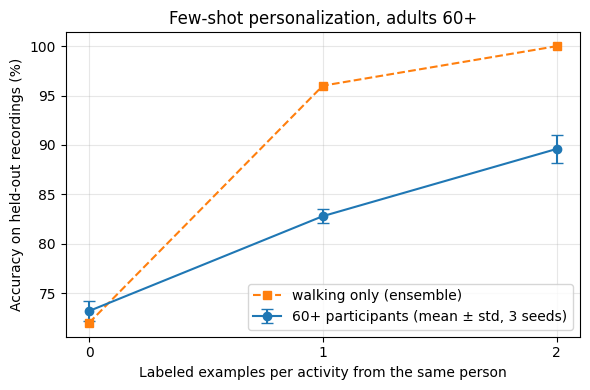

In [10]:
import copy

def freeze_bn(model):
    for m in model.modules():
        if isinstance(m, torch.nn.BatchNorm2d):
            m.eval()                                    # keep pretrained running statistics

def personalize(base, shot_ix, steps=30, lr=1e-4):
    model = copy.deepcopy(base)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    b = torch.tensor(shot_ix, device=device)
    for _ in range(steps):
        model.train(); freeze_bn(model)
        loss = F.cross_entropy(model(augment(Z[b].clone())), y[b])
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return model

# --- plan: which recordings are examples and which are test, per person ---
rng = np.random.RandomState(0)
plan = {}
for subj, g in meta[meta["split"] == "test_60plus"].groupby("subject"):
    shots1, shots2, test = [], [], []
    for act, ga in g.groupby("label"):
        r = rng.permutation(ga.index.values)
        test.append(r[-1])                              # last one held out for testing
        if len(r) >= 2: shots1.append(r[0]); shots2.append(r[0])
        if len(r) >= 3: shots2.append(r[1])
    plan[subj] = (np.array(shots1), np.array(shots2), np.array(test))
subjects = sorted(plan)
test_all = np.concatenate([plan[s][2] for s in subjects])
labels_all = meta["label"].values[test_all]
print(f"{len(subjects)} participants, {len(test_all)} held-out test recordings")

# --- run: k = 0, 1, 2 for each of the 3 trained models ---
P = {k: [] for k in [0, 1, 2]}
t0 = time.time()
for seed in [0, 1, 2]:
    base = timm.create_model("resnet18", pretrained=False, num_classes=5, in_chans=1, drop_rate=0.2).to(device)
    base.load_state_dict(torch.load(os.path.join(CKPT_DIR, f"per_person_seed{seed}.pt"), map_location=device))
    set_seed(seed)
    P[0].append(predict_probs(base, test_all))
    for k in [1, 2]:
        probs = [predict_probs(personalize(base, plan[s][k - 1]), plan[s][2]) for s in subjects]
        P[k].append(np.concatenate(probs))
    print(f"seed {seed} done ({time.time()-t0:.0f}s)")

# --- results ---
rows = []
for k in [0, 1, 2]:
    per_seed = [(p.argmax(1) == labels_all).mean() * 100 for p in P[k]]
    ens = np.mean(P[k], axis=0).argmax(1)
    rows.append({"labeled examples per activity": k,
                 "accuracy (mean of seeds)": np.mean(per_seed), "std": np.std(per_seed),
                 "ensemble accuracy": (ens == labels_all).mean() * 100,
                 **{f"ens: {n}": (ens[labels_all == c] == c).mean() * 100 for c, n in enumerate(names)}})
fewshot = pd.DataFrame(rows).set_index("labeled examples per activity").round(1)
fewshot.to_csv(os.path.join(RESULTS_DIR, "fewshot_personalization.csv"))
print(fewshot.T.to_string())

plt.figure(figsize=(6, 4))
plt.errorbar(fewshot.index, fewshot["accuracy (mean of seeds)"], yerr=fewshot["std"], marker="o",
             capsize=4, label="60+ participants (mean ± std, 3 seeds)")
plt.plot(fewshot.index, fewshot["ens: walking"], "s--", label="walking only (ensemble)")
plt.xticks([0, 1, 2]); plt.xlabel("Labeled examples per activity from the same person")
plt.ylabel("Accuracy on held-out recordings (%)"); plt.title("Few-shot personalization, adults 60+")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fewshot_personalization.png"), dpi=150); plt.show()